In [216]:
import pandas as pd
import numpy as np
import yfinance as yf
from fredapi import Fred
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from backtesting import Strategy, Backtest
from datetime import datetime, timedelta
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

In [217]:
df = yf.download("JPM", period="10y", interval="1d")
df.columns = df.columns.get_level_values(0)
df = df.reset_index()
df['Date'] = pd.to_datetime(df['Date'])
del df['Volume']

[*********************100%***********************]  1 of 1 completed


In [218]:
def BOP(data, n):
    bop = ((data['Close'] - data['Open']) / (data['High'] - data['Low']))
    sbop = bop.rolling(n).mean()
    hist1 = bop - sbop
    hist2 = hist1.rolling(n).mean()
    hist = hist2.rolling(8).mean()
    return bop, sbop, hist
           
df["BOP"], df["SBOP"], df['histo'] = BOP(df, 17)
df

Price,Date,Close,High,Low,Open,BOP,SBOP,histo
0,2016-10-14,52.035275,53.198980,51.865733,53.021730,-0.739890,NaN,NaN
1,2016-10-17,51.765545,52.243359,51.434159,51.958211,-0.238095,NaN,NaN
2,2016-10-18,52.174000,52.567040,52.050696,52.289601,-0.223883,NaN,NaN
3,2016-10-19,52.674911,52.790512,52.258752,52.258752,0.782607,NaN,NaN
4,2016-10-20,52.605560,52.929238,52.358948,52.466840,0.243244,NaN,NaN
...,...,...,...,...,...,...,...,...
2507,2026-10-07,329.579987,329.869995,325.070007,327.200012,0.495829,-0.173511,-0.075616
2508,2026-10-08,331.420013,332.309998,325.630005,327.250000,0.624254,-0.144326,-0.066800
2509,2026-10-09,332.989990,333.540009,330.579987,331.200012,0.604718,-0.084708,-0.044686
2510,2026-10-12,334.299988,336.339996,333.549988,334.299988,0.000000,-0.063669,-0.017938


In [219]:

def signal(data):
    signal = [0] * len(df)
    for i in range(0,len(df)):
        if (data.histo.iloc[i] < 0) &\
        (data.histo.iloc[i] > data.histo.iloc[i-1]):
            signal[i] = 1
        elif (data.histo.iloc[i-1] > 0) &\
        (data.histo.iloc[i] < 0):
            signal[i] = 2
        elif (data.SBOP.iloc[i-1] < -0.1) &\
        (data.SBOP.iloc[i] > -0.1):
            signal[i] = 3
        else:
            signal[i] = 0
        df["signal"] = signal  

signal(df)

def long_entries(x):
    offset = 0.002
    if x['signal']==1:
        return x['Low'] * (1-offset)
    else:
        return np.nan

df['long_entries'] = df.apply(lambda x: long_entries(x), axis=1)

def more_long_entries(x):
    offset = 0.002
    if x['signal']==3:
        return x['Low'] * (1-offset)
    else:
        return np.nan

df['more_long_entries'] = df.apply(lambda x: more_long_entries(x), axis=1)

def short_entries(x):
    offset = 0.002
    if x['signal']==2:
        return x['High'] * (1+offset)
    else:
        return np.nan

df['short_entries'] = df.apply(lambda x: short_entries(x), axis=1)


print(df['signal'].value_counts())
df.shape

signal
0    1811
1     592
2      75
3      34
Name: count, dtype: int64


(2512, 12)

In [220]:
df.set_index('Date', inplace=True)

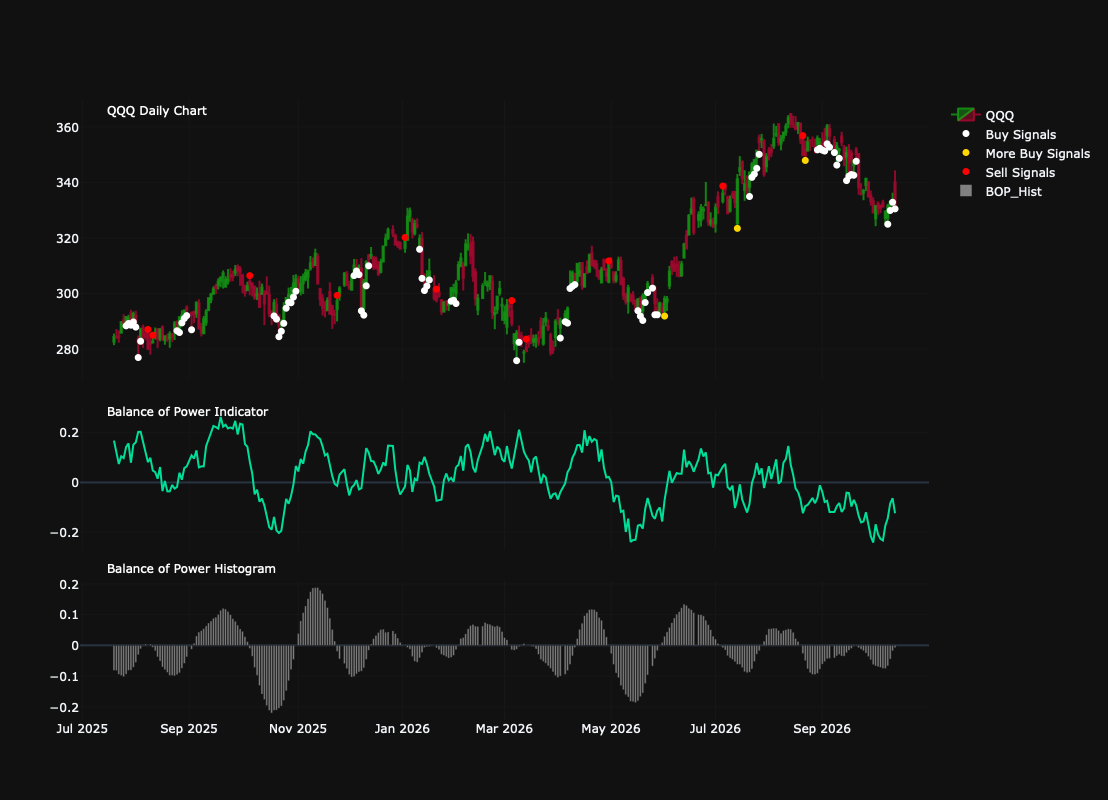

In [221]:
bar = 2200
df1 = df[bar:bar+350].copy()

fig = make_subplots(rows=3, cols=1, shared_xaxes=True, 
                    row_heights=[0.50, 0.25, 0.25], 
                    vertical_spacing=0.05)

fig.add_trace(go.Candlestick(x = df1.index, 
                            open = df1['Open'],
                            high = df1['High'],
                            low = df1['Low'],
                            close = df1['Close'],
                            increasing_line_color = 'rgba(19,156,19,0.8)',
                            decreasing_line_color = 'rgba(175,07,49,0.8)',
                            name = 'QQQ'),
                            row=1, col=1)

fig.add_scatter(x=df1.index, y=df1['long_entries'], mode="markers",
                marker=dict(size=7, color="White"),
                name="Buy Signals")

fig.add_scatter(x=df1.index, y=df1['more_long_entries'], mode="markers",
                marker=dict(size=7, color="gold"),
                name="More Buy Signals")

fig.add_scatter(x=df1.index, y=df1['short_entries'], mode="markers",
                marker=dict(size=7, color="red"),
                name="Sell Signals")

fig.add_trace(go.Scatter(x=df1.index, 
                         y=df1.SBOP, 
                         line=dict(color="#00DF9A", width=2),
                         name='Balance of Power',
                         showlegend=False),
                         row=2, col=1)

fig.add_trace(go.Bar(x=df1.index, 
                     y=df1['histo'], 
                     name="BOP_Hist",
                     marker=dict(color='gray')),
                     row=3, col=1)

fig.update_layout(
    annotations=[dict(text="Balance of Power Indicator",
                    font=dict(color="white", size=12),
                    xref="paper",
                    yref="paper",
                    x=0.03,
                    y=0.5,
                    showarrow=False),
                dict(text="Balance of Power Histogram",
                    font=dict(color="white", size=12),
                    xref="paper",
                    yref="paper",
                    x=0.03,
                    y=0.23,
                    showarrow=False),
                dict(text="QQQ Daily Chart",
                    font=dict(color="white", size=12),
                    xref="paper",
                    yref="paper",
                    x=0.03,
                    y=1.0,
                    showarrow=False)])

fig.update_layout(autosize=False, width=1100, height=800, 
                  xaxis_rangeslider_visible=False, template="plotly_dark")

fig.update_xaxes(gridcolor="#171717") 
fig.update_yaxes(gridcolor="#171717")

fig.update_xaxes(
    rangebreaks=[
        dict(bounds=["sat", "mon"]),
    ])

fig.show()

In [222]:
def SIGNAL():
    return df.signal

class MyStrat(Strategy):
    
    def init(self):
        super().init()
        self.signal = self.I(SIGNAL)

    def next(self):
        super().next()
        
        price = self.data.Close[-1]
        
        if self.signal==1: 
            if self.position.is_short or not self.position:
                self.position.close()
                self.buy(size=0.99, sl=0.94*price, tp=1.03*price)

        elif self.signal==3: 
            if self.position.is_short or not self.position:
                self.position.close()
                self.buy(size=0.99, sl=0.92*price, tp=1.035*price)
        
        elif self.signal==2:
            if self.position.is_long or not self.position:
                self.position.close()

bt = Backtest(df, MyStrat, cash=100_000, margin=1, exclusive_orders=True, commission=0.0005)
stats = bt.run()
stats

Start                     2016-10-14 00:00:00
End                       2026-10-13 00:00:00
Duration                   3651 days 00:00:00
Exposure Time [%]                   45.382166
Equity Final [$]                433343.398031
Equity Peak [$]                 462080.593752
Return [%]                         333.343398
Buy & Hold Return [%]              536.933303
Return (Ann.) [%]                   15.847331
Volatility (Ann.) [%]                16.65142
Sharpe Ratio                          0.95171
Sortino Ratio                        1.772545
Calmar Ratio                         0.677543
Max. Drawdown [%]                  -23.389411
Avg. Drawdown [%]                   -2.722266
Max. Drawdown Duration      476 days 00:00:00
Avg. Drawdown Duration       33 days 00:00:00
# Trades                                  147
Win Rate [%]                        68.027211
Best Trade [%]                       7.686788
Worst Trade [%]                     -7.744405
Avg. Trade [%]                    

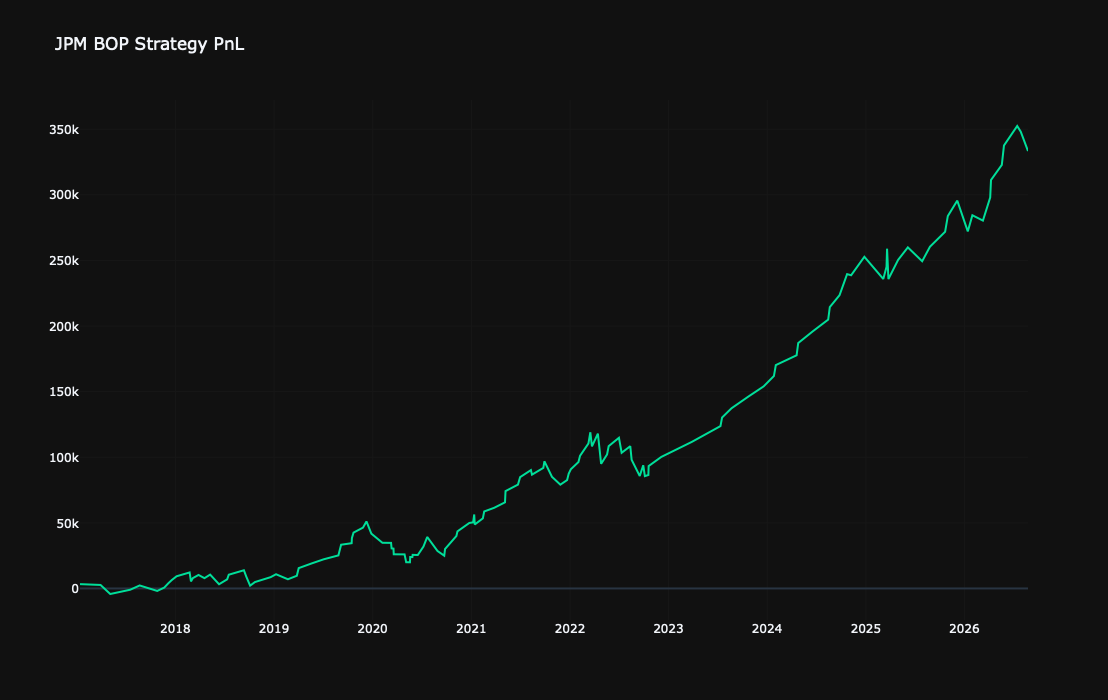

In [223]:
trades = stats['_trades']
trades['CumulativePnL'] = trades['PnL'].cumsum()

fig_trades = go.Figure()

fig_trades.add_trace(go.Scatter(x=trades['EntryTime'], 
                                      y=trades['CumulativePnL'], 
                                      mode='lines', 
                                      name='Cumulative PnL', 
                                      line=dict(color='#00df9a')))

fig_trades.update_layout(title='JPM BOP Strategy PnL',
                         template="plotly_dark",
                         autosize=False,
                         width=1100,
                         height=700,
                        )

fig_trades.update_yaxes(gridcolor="#171717")
fig_trades.update_xaxes(gridcolor="#171717")

fig_trades.write_image("PNL.png", scale=2)

fig_trades.show()

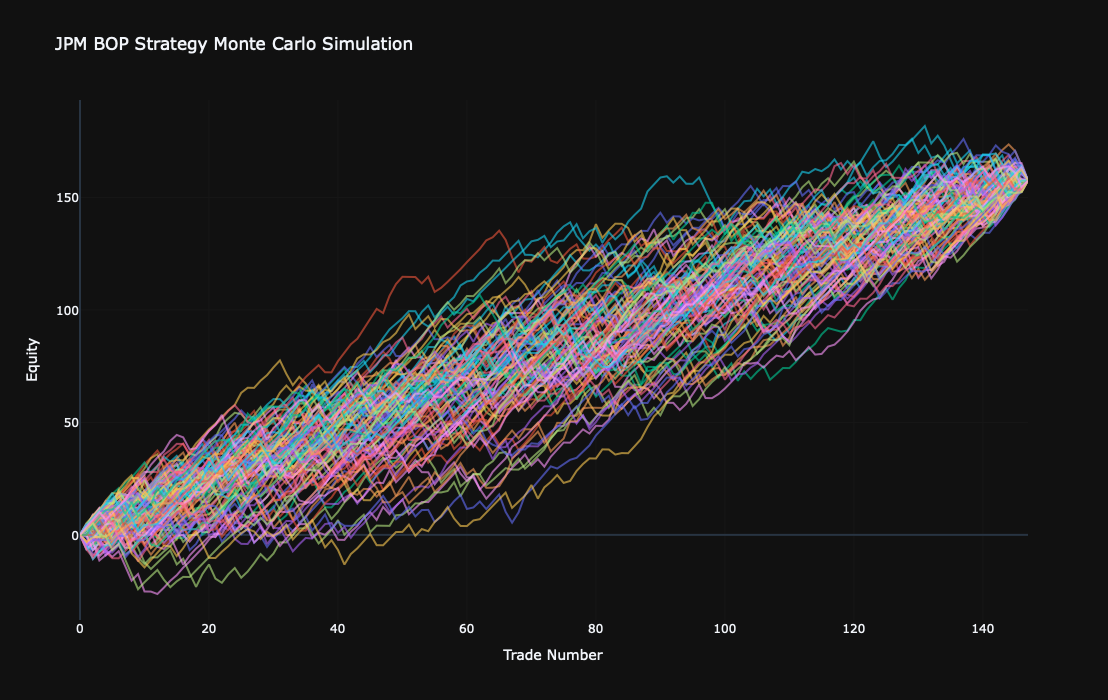

In [224]:
def randomised_trades(trades):
    cumulative_return = [0]

    for pct in trades['ReturnPct']:
        cumulative_return.append(cumulative_return[-1] + (pct * 100))

    return cumulative_return

simulations = 100
curves = []

for i in range(simulations):
    new_trades = trades.sample(frac=1).reset_index(drop=True)
    equity_curve = randomised_trades(new_trades)
    curves.append(equity_curve)

mc = go.Figure()

for equity_curve in curves:
    mc.add_trace(go.Scatter(y=equity_curve, mode='lines', opacity=0.6, showlegend=False))

mc.update_layout(
    title='JPM BOP Strategy Monte Carlo Simulation',
    xaxis_title='Trade Number',
    yaxis_title='Equity',
    template="plotly_dark",
    autosize=False,
    width=1100,
    height=700,
)

mc.update_yaxes(gridcolor="#171717")
mc.update_xaxes(gridcolor="#171717")

mc.show()